# Когорты, второй заказ и проверяемая инициатива
## Краткий результат
37,14% покупателей имеют второй заказ за всё доступное наблюдение. Продолжительность наблюдения у этих клиентов различается. На зрелой 180-дневной базе второй заказ сделали **1 342 из 12 503 (10,73%)**.

Предложение: проверить одно сообщение с дополняющими аксессуарами без скидки на 31-й день после первой корзины Accessories, если второго заказа ещё нет. При гипотезе +2 п.п. и указанных ниже затратах сценарная прибыль на 1 000 контактов **+121,49**. Эффект рассылки пока не измерен; расчёт показывает результат заданного сценария.

## Контекст и методы
Различаем возврат **именно в месяце M**, накопленную долю вторых заказов **за H дней** и Kaplan–Meier с цензурированием. В Mixed попадают первые корзины с несколькими категориями. Порядок заказов внутри одного дня условный: order_number; таких вторых заказов 8, они считаются возвратом на день 0.

### Допущения
Данные учебные. Первые покупки до начала наблюдения неизвестны; новые когорты нельзя считать полной историей привлечения. Наблюдение заканчивается общей датой выгрузки. При этом поведение клиентов могло различаться в разные периоды.

In [1]:
from pathlib import Path
import os, json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import psycopg2
from decimal import Decimal
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
conn = psycopg2.connect(os.environ.get('DATABASE_URL', ''))
def query(sql):
    with conn.cursor() as cur:
        cur.execute(sql)
        df = pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])
        for col in df.columns:
            if any(isinstance(v, Decimal) for v in df[col]):
                df[col] = df[col].map(lambda v: float(v) if v is not None else np.nan)
        return df
plt.rcParams.update({'figure.figsize': (10, 4.2), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, GOLD = '#245b78', '#c88a28'
pd.options.display.float_format = '{:,.3f}'.format
query('SELECT * FROM portfolio.settings')

,observation_start,as_of_date
0,2010-12-29,2014-01-29


## Когорты: календарный M1, M3, M6

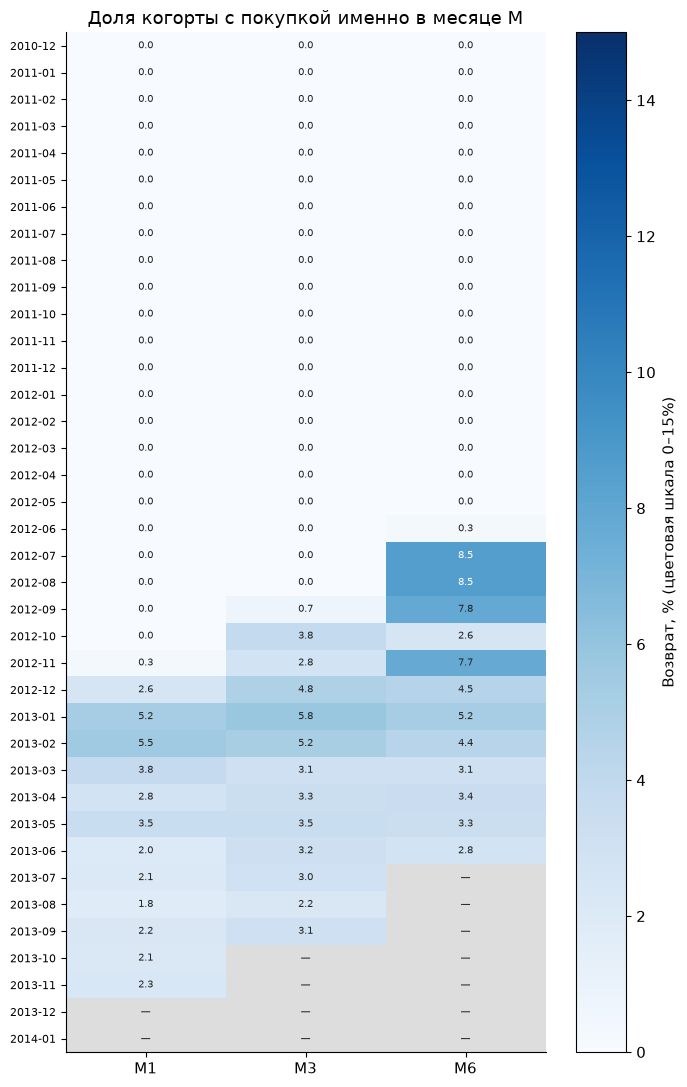

In [2]:
cohort=query('SELECT * FROM portfolio.cohort_retention WHERE month_age IN (1,3,6) ORDER BY cohort,month_age')
p=cohort.pivot(index='cohort',columns='month_age',values='retention').astype(float)
fig,ax=plt.subplots(figsize=(7,11));cmap=plt.get_cmap('Blues').copy();cmap.set_bad('#dddddd')
im=ax.imshow(p.to_numpy()*100,aspect='auto',vmin=0,vmax=15,cmap=cmap)
ax.set_xticks(range(3),['M1','M3','M6']);ax.set_yticks(range(len(p)),[str(x)[:7] for x in p.index],fontsize=8)
for i in range(len(p)):
    for j in range(3):
        v=p.iloc[i,j];ax.text(j,i,'—' if pd.isna(v) else f'{v*100:.1f}',ha='center',va='center',fontsize=7,color='white' if v>.08 else '#222')
fig.colorbar(im,ax=ax,label='Возврат, % (цветовая шкала 0–15%)');ax.set_title('Доля когорты с покупкой именно в месяце M');plt.tight_layout();plt.show()

Серые ячейки обозначают периоды, которые ещё нельзя наблюдать полностью. Значение возврата в них остаётся неизвестным. Полноту целевого месяца проверяем по его правой границе. Покупка через 6 месяцев не требует покупок в M1 и M3: retention не обязан убывать.

In [3]:
query('SELECT * FROM portfolio.cohort_summary ORDER BY month_age')

,month_age,cohorts,eligible,active,retention
0,1,31,"11,414.000",223.000,0.020
1,3,31,"11,414.000",262.000,0.023
2,6,31,"11,414.000",323.000,0.028


Общий профиль M1/M3/M6 использует один и тот же набор 31 когорт (11 414 клиентов), зрелых до M6: 1,95%, 2,30%, 2,83%. Начальная когорта декабря 2010 наблюдается только с 29-го числа и особенно подвержена левому усечению. Ранние нулевые значения и более позднее появление аксессуаров показывают, что состав продаж менялся. Это ограничивает применимость среднего профиля к современному магазину.

## Второй заказ: фиксированное окно и цензурирование

In [4]:
repeat=query('SELECT * FROM portfolio.repeat_horizons ORDER BY days,first_category')
r=repeat[repeat.days==180].copy();r['repeat_rate']=r.repeat_rate.astype(float)
r[['first_category','eligible','repeated','repeat_rate']]

,first_category,eligible,repeated,repeat_rate
8,Accessories,3537,699,0.198
9,Bikes,5632,215,0.038
10,Clothing,615,168,0.273
11,Mixed,2719,260,0.096


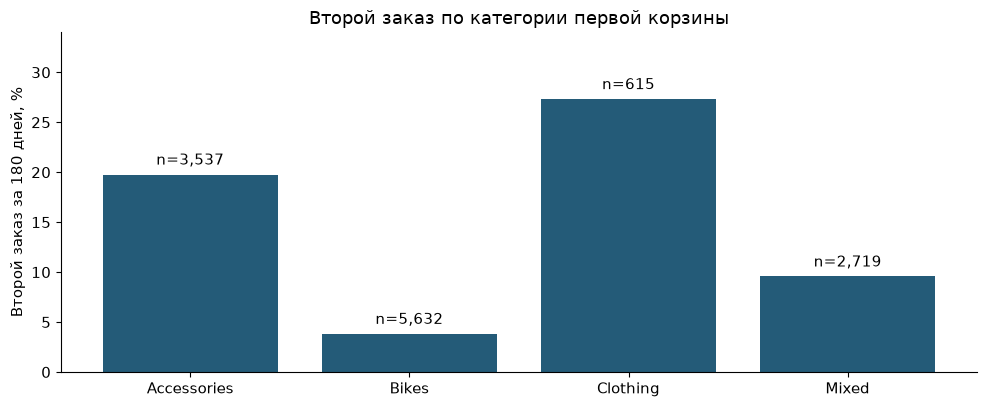

In [5]:
fig,ax=plt.subplots();ax.bar(r.first_category,r.repeat_rate*100,color=BLUE)
for i,row in enumerate(r.itertuples()):ax.text(i,row.repeat_rate*100+1,f'n={row.eligible:,}',ha='center')
ax.set_ylim(0,34);ax.set_ylabel('Второй заказ за 180 дней, %');ax.set_title('Второй заказ по категории первой корзины');plt.tight_layout();plt.show()

Разные категории представлены в разные периоды. Дополнительная проверка ниже ограничивает базу январём–июнем 2013 и использует одинаковые веса месячных когорт. Это уменьшает календарное смешение, но не устраняет различия в клиентах и товарах. У Bikes лишь 176 клиентов в этом сравнении.

In [6]:
query('SELECT * FROM portfolio.category_standardized ORDER BY first_category')

,first_category,eligible,standardized_rate,months
0,Accessories,"2,991.000",0.205,6
1,Bikes,176.000,0.035,6
2,Clothing,526.000,0.254,6
3,Mixed,"2,266.000",0.099,6


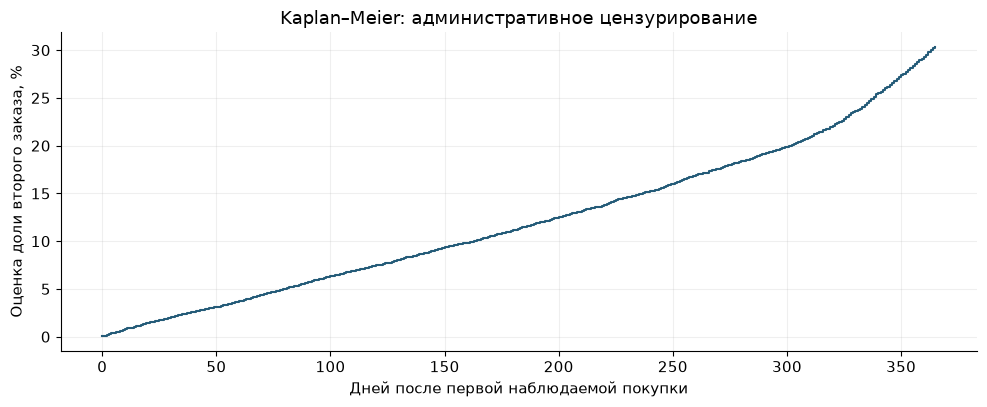

,median_among_repeaters
0,369.000


In [7]:
km=query('SELECT * FROM portfolio.km_second_order ORDER BY day')
view=km[km.day<=365]
plt.step(view.day,view.cumulative_repeat.astype(float)*100,where='post',color=BLUE)
plt.xlabel('Дней после первой наблюдаемой покупки');plt.ylabel('Оценка доли второго заказа, %');plt.title('Kaplan–Meier: административное цензурирование');plt.grid(alpha=.2);plt.tight_layout();plt.show()
query("SELECT percentile_cont(0.5) WITHIN GROUP (ORDER BY days_to_second) AS median_among_repeaters FROM portfolio.customer_mart WHERE days_to_second IS NOT NULL")

В product-limit оценке каждый день S(t) умножается на (1 − events / at_risk); цензурированные покидают риск после этого дня. Оценка возврата по Kaplan–Meier составляет 11,14% к 180 дням и 30,35% к 365 дням. Метод учитывает доступное наблюдение каждого клиента, поэтому его база отличается от базы фиксированных окон. Медиана только среди вернувшихся смещена отбором; KM-медиана 508 дней также зависит от сильного допущения сопоставимости когорт. Для расчёта кампании используем сегмент клиентов, полностью наблюдаемый в выбранном окне.

## Инициатива и сценарная окупаемость

In [8]:
query("SELECT * FROM portfolio.campaign_baseline WHERE first_category='Accessories'")

,first_category,eligible,repeat_31_120,baseline_rate,second_order_aov
0,Accessories,4329,443,0.102,53.070


У 4 329 покупателей первой корзины Accessories, без повтора к 30-му дню и с наблюдением до дня 120, 443 сделали второй заказ в дни 31–120. База **10,23%**, средний чек этих вторых заказов **53,07**. На дату среза найдено 416 клиентов с одной покупкой 30–60 дней назад. Это помогает оценить размер сегмента. Для реальной рассылки дополнительно нужны контакты и согласия.

Инициатива: одно сообщение на день 31 с дополняющими аксессуарами по первой корзине, без скидки. Предполагается, что подходящее дополнение к первой покупке заинтересует клиента. Это предположение проверяется экспериментом. Разница с контрольной группой измеряется по назначению (ITT), включая недоставленные сообщения.

In [9]:
scenarios=pd.read_json(ROOT/'outputs/scenarios.json')
scenarios[['discount','uplift_pp','incremental_orders','incremental_revenue','total_campaign_cost','incremental_profit','roi','break_even_pp']]

,discount,uplift_pp,incremental_orders,incremental_revenue,total_campaign_cost,incremental_profit,roi,break_even_pp
0,0.000,0,0,0.000,250.000,-250.000,-1.000,1.346
1,0.000,1,10,530.700,250.000,-64.255,-0.257,1.346
2,0.000,2,20,"1,061.400",250.000,121.490,0.486,1.346
3,0.000,4,40,"2,122.799",250.000,492.980,1.972,1.346
4,0.050,0,0,0.000,521.541,-521.541,-1.000,3.276
5,0.050,1,10,530.700,548.076,-362.331,-0.661,3.276
6,0.050,2,20,"1,061.400",574.611,-203.121,-0.353,3.276
7,0.050,4,40,"2,122.799",627.681,115.299,0.184,3.276


Формула дополнительной прибыли:

`N × Δp × A × m − N × c − F − N × (p₀ + Δp) × A × d`.

В расчёте N=1 000 задаёт число контактов, A=53,07 средний чек, p₀=10,23% историческую конверсию. Маржа m=35%, цена контакта c=0,15, расходы на настройку F=100 и скидка d=0% либо 5% заданы как **допущения**. Расчёт учитывает один второй заказ на клиента. Скидка субсидирует и тех, кто купил бы сам. При +2 п.п. без скидки +121,49, со скидкой 5% −203,12. Пороги окупаемости +1,35 и +3,28 п.п. соответственно.

Главная неопределённость состоит в том, изменит ли сообщение поведение покупателей. Возможен сценарий, при котором сообщение создаёт расходы и раздражает клиента, не увеличивая число покупок. Инициатива разумна при доступном согласованном канале, актуальном ассортименте и подтверждённой марже.

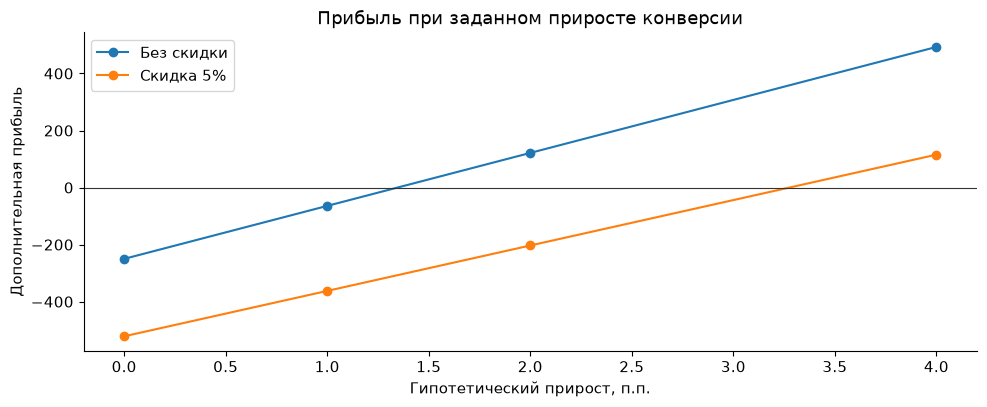

In [10]:
fig,ax=plt.subplots()
for discount,g in scenarios.groupby('discount'):
    ax.plot(g.uplift_pp,g.incremental_profit,marker='o',label='Без скидки' if discount==0 else 'Скидка 5%')
ax.axhline(0,color='#333',lw=.8);ax.set_xlabel('Гипотетический прирост, п.п.');ax.set_ylabel('Дополнительная прибыль');ax.legend();ax.set_title('Прибыль при заданном приросте конверсии');plt.tight_layout();plt.show()

## Дизайн эксперимента и решение
На 31-й день подходящих клиентов с согласием на контакт случайно распределяют между двумя равными группами. Назначенную группу сохраняют в данных. При распределении учитывают месяц входа и диапазон чека. Группу клиента сохраняют до конца эксперимента; пересекающиеся кампании исключают. Основная метрика показывает долю назначенных клиентов со вторым оплаченным неотменённым заказом в дни 31–120. В расчёте сохраняют всех назначенных клиентов по принципу ITT. Для принятия решения считают дополнительную маржинальную прибыль на назначенного клиента после всех расходов. Также отслеживают возвраты, жалобы, отписки и расходы на скидки. Допустимые пределы этих показателей согласуют до старта.

Для обнаружения +2 п.п. от 10,23%: двустороннее α=5%, мощность 80%, нормальная аппроксимация двух долей даёт **3 913 на группу**. Этот размер выборки рассчитан для конверсии. Для прибыли нужна её дисперсия и отдельный расчёт. 416 текущих кандидатов недостаточно; нужен поток новых когорт. Длительность включает набор нужного числа клиентов и 90 дней наблюдения каждого участника. Точная дата окончания зависит от скорости набора.

До анализа зафиксировать размер выборки, правила исключений, основную метрику и процедуру. Проверить соответствие размеров групп плану 50/50, повторные назначения и доставку. Не останавливаться при случайном p<0,05. Оценить разность долей с 95% ДИ и прибыль с клиентским bootstrap-интервалом. Расширять кампанию следует при подтверждённом полезном экономическом эффекте и приемлемом уровне побочных последствий. A/B-тест не проводился.

## Что сделано и что нужно защитить
SQL, проверки, графики и формулировки этой версии подготовлены с помощью ИИ. Самостоятельное владение пользователя не проверялось. Для интервью нужно уметь заново построить orders, объяснить знаменатели, NULL незрелых когорт, сумму вкладов и расходы на скидку для клиентов, которые купили бы сами. См. `docs/interview.md`.

In [11]:
conn.close()